# 02 - Clasificación

Dos técnicas × 5 configuraciones de hiperparámetros, evaluadas con cross-validation (Tarea 2).

**Decisiones del grupo:**
- **Técnicas:** Árbol de decisión (Clase 3) y Regresión logística (Clase 7). Son modelos muy distintos entre sí (reglas vs. lineal), lo que además favorece al Stacking de la Tarea 3.
- **Cross-validation:** `StratifiedKFold` de 10 folds, con los **mismos folds** para todos los modelos.
- **`Student ID` y `Est_Topic_Level`** (estudiante × tema × nivel, creada en el EDA): target encoding **dentro de cada fold** (en un `Pipeline`), para evitar *data leakage*.
- **Métricas (Clase 4):** accuracy, precision, recall, F1 y AUC-ROC, con clase positiva 1 = respuesta correcta.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # para poder importar src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
import sklearn
print('scikit-learn', sklearn.__version__)  # se necesita 1.8 o superior (por TargetEncoder y l1_ratio)

from src.utils import TARGET, DATOS_PROCESADOS, RAIZ

RESULTADOS = RAIZ / 'resultados'
SEMILLA = 42

scikit-learn 1.9.1


## 1. Carga de datos

Se usa el dataset generado por el notebook 01 (hay que correrlo antes).

In [2]:
df = pd.read_csv(DATOS_PROCESADOS / 'datos_procesados.csv')

X = df.drop(columns=TARGET)
y = df[TARGET]

print('X:', X.shape, '| y:', y.shape)
print(y.value_counts(normalize=True).round(3))

X: (9546, 240) | y: (9546,)
Type of Answer
0    0.532
1    0.468
Name: proportion, dtype: float64


## 2. Esquema de evaluación

- **Folds:** `StratifiedKFold` con 10 folds y semilla fija. Así todos los modelos (y el Stacking del notebook 03) se evalúan sobre exactamente las mismas particiones.
- **Pipeline:** `TargetEncoder` sobre `Student ID` y `Est_Topic_Level` → modelo. Como el encoder está dentro del pipeline, en cada fold el historial de cada estudiante (en general, y en cada tema y nivel) se calcula **solo con los datos de train**. Los estudiantes o combinaciones que no están en train reciben el promedio general. El resto de las columnas (ya numéricas) pasa sin cambios.
- No se escalan las variables: todas quedan entre 0 y 1 (binarias, o la tasa de acierto del target encoding).
- **No se reporta el accuracy en train.** Dentro del train, `TargetEncoder` calcula el historial con un CV interno (*cross-fitting*) para que el modelo no se entrene con información de la propia respuesta. Al predecir sobre ese mismo train, en cambio, usa el historial completo. Como el modelo ve valores distintos al entrenar y al predecir, el accuracy en train no mide la memorización real y no sirve para detectar overfitting. El overfitting se detecta comparando las métricas de test a medida que aumenta la complejidad del modelo.

In [3]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)

METRICAS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# Columnas que se codifican con target encoding (el resto ya es numérico)
COLS_TE = ['Student ID', 'Est_Topic_Level']


def crear_pipeline(modelo, cols_te=COLS_TE):
    """Target encoding de las columnas cols_te (dentro de cada fold) + modelo."""
    encoder = ColumnTransformer(
        [('target_encoding', TargetEncoder(target_type='binary',
                                           cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA)),
          cols_te)],
        remainder='passthrough',
    )
    return make_pipeline(encoder, modelo)


def evaluar(nombre, modelo, X, y, cols_te=COLS_TE):
    """Evalúa un modelo con cross-validation y devuelve el promedio y el desvío de cada métrica."""
    res = cross_validate(crear_pipeline(modelo, cols_te), X, y, cv=cv, scoring=METRICAS)
    fila = {'modelo': nombre}
    for m in METRICAS:
        fila[m] = res[f'test_{m}'].mean()
        fila[f'{m}_std'] = res[f'test_{m}'].std()
    return fila


def ic95(valores):
    """Media e intervalo de confianza del 95 % (distribución t de Student)."""
    valores = np.asarray(valores)
    n = len(valores)
    media = valores.mean()
    margen = stats.t.ppf(0.975, n - 1) * valores.std(ddof=1) / np.sqrt(n)
    return media, media - margen, media + margen

## 3. Selección de características: ¿aportan las keywords?

En el EDA vimos que las 191 keywords generan columnas muy dispersas y que la mayoría pertenece a un único subtopic. Antes de entrenar los 10 modelos, se comparan tres conjuntos de columnas usando una configuración intermedia de cada técnica:

| Conjunto | Columnas |
|---|---|
| A. Sin keywords | Student ID, Est_Topic_Level, Level, Country, Topic, Subtopic |
| B. Top 30 keywords | A + las 30 keywords más frecuentes |
| C. Todas las keywords | A + las 191 keywords |

In [4]:
cols_kw = [c for c in X.columns if c.startswith('KW_')]
cols_sin_kw = [c for c in X.columns if not c.startswith('KW_')]
top30_kw = X[cols_kw].sum().sort_values(ascending=False).head(30).index.tolist()

conjuntos = {
    'A. Sin keywords': cols_sin_kw,
    'B. Top 30 keywords': cols_sin_kw + top30_kw,
    'C. Todas las keywords': cols_sin_kw + cols_kw,
}

modelos_base = {
    'Árbol (max_depth=8)': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA),
    'Reg. logística (C=1)': LogisticRegression(C=1, max_iter=2000),
}

filas = []
for nombre_conj, cols in conjuntos.items():
    for nombre_mod, modelo in modelos_base.items():
        fila = evaluar(nombre_mod, modelo, X[cols], y)
        fila['conjunto'] = nombre_conj
        fila['n_columnas'] = len(cols)
        filas.append(fila)

sel = pd.DataFrame(filas)
display(sel.pivot_table(index=['conjunto', 'n_columnas'], columns='modelo',
                        values=['accuracy', 'f1', 'roc_auc']).round(3))

accuracy                      \
modelo                           Reg. logística (C=1) Árbol (max_depth=8)   
conjunto              n_columnas                                            
A. Sin keywords       49                        0.669               0.660   
B. Top 30 keywords    79                        0.667               0.657   
C. Todas las keywords 240                       0.671               0.660   

                                                   f1                      \
modelo                           Reg. logística (C=1) Árbol (max_depth=8)   
conjunto              n_columnas                                            
A. Sin keywords       49                        0.641               0.644   
B. Top 30 keywords    79                        0.638               0.638   
C. Todas las keywords 240                       0.644               0.642   

                                              roc_auc                      
modelo                           Reg. logística (C=1) Árbol (max_depth=8)  
conjunto              n_columnas                                           
A. Sin keywords       49                        0.723               0.707  
B. Top 30 keywords    79                        0.722               0.705  
C. Todas las keywords 240                       0.722               0.707

**Conclusión:** las keywords casi no aportan información. Pasar de 49 columnas (sin keywords) a 240 (todas) mejora el accuracy de la regresión logística apenas de 0,669 a 0,671 y deja al árbol igual (0,660). El AUC no cambia: se mantiene entre 0,722 y 0,723 para la logística y entre 0,705 y 0,707 para el árbol. Esto es coherente con lo observado en el EDA: la mayoría de las keywords pertenece a un único subtopic, por lo que su información ya está contenida en la variable `Subtopic`.

Ante un rendimiento equivalente, elegimos el **conjunto A (sin keywords, 49 columnas)**, ya que es el modelo más simple: entrena más rápido, es más fácil de interpretar y reduce el riesgo de sobreajuste por tener muchas columnas dispersas.

In [5]:
# Conjunto de columnas elegido para el resto del TP (cambiar si el grupo decide otro)
COLUMNAS = conjuntos['A. Sin keywords']
X_sel = X[COLUMNAS]
print('Columnas usadas:', X_sel.shape[1])

Columnas usadas: 49


### 3.2 ¿Aporta la variable `Est_Topic_Level`?

En el EDA (§5.3) vimos que el nivel de un mismo estudiante cambia según el tema y el nivel de la pregunta. Se compara el conjunto elegido con y sin la variable `Est_Topic_Level`, usando las mismas configuraciones intermedias. En los dos casos se conserva `Student ID`.

In [6]:
# Mismo conjunto de columnas, con y sin la variable Est_Topic_Level
X_sin_etl = X_sel.drop(columns='Est_Topic_Level')

filas = []
for nombre_mod, modelo in modelos_base.items():
    sin = evaluar(nombre_mod, modelo, X_sin_etl, y, cols_te=['Student ID'])
    con = evaluar(nombre_mod, modelo, X_sel, y)
    filas += [{**sin, 'variante': 'Sin Est_Topic_Level'}, {**con, 'variante': 'Con Est_Topic_Level'}]

aporte_etl = pd.DataFrame(filas)
display(aporte_etl.pivot_table(index='variante', columns='modelo',
                               values=['accuracy', 'f1', 'roc_auc']).round(3))

accuracy                      \
modelo              Reg. logística (C=1) Árbol (max_depth=8)   
variante                                                       
Con Est_Topic_Level                0.669               0.660   
Sin Est_Topic_Level                0.650               0.646   

                                      f1                      \
modelo              Reg. logística (C=1) Árbol (max_depth=8)   
variante                                                       
Con Est_Topic_Level                0.641               0.644   
Sin Est_Topic_Level                0.622               0.640   

                                 roc_auc                      
modelo              Reg. logística (C=1) Árbol (max_depth=8)  
variante                                                      
Con Est_Topic_Level                0.723               0.707  
Sin Est_Topic_Level                0.705               0.696

**Conclusión:** la variable `Est_Topic_Level` mejora a las dos técnicas. La regresión logística pasa de 0,650 a 0,669 de accuracy y de 0,705 a 0,723 de AUC, y el árbol pasa de 0,646 a 0,660 de accuracy y de 0,696 a 0,707 de AUC. La mejora es de 1,4 a 1,9 puntos de accuracy: es moderada, pero aparece en los dos modelos. En la logística mejoran todas las métricas. En el árbol mejoran el accuracy, la precision, el F1 y el AUC, mientras que el recall baja un poco (de 0,673 a 0,657): el árbol se vuelve algo más conservador para predecir "correcta", pero se equivoca menos en general. Esto confirma lo observado en el EDA (§5.3): saber cómo le va a un estudiante en un tema y nivel específicos predice mejor que su tasa de acierto general. Por eso, **se incorpora `Est_Topic_Level`** a todos los modelos de la Tarea 2 y del Stacking.

## 4. Técnica 1: Árbol de decisión

Se varían la profundidad, el mínimo de muestras por hoja y el criterio de división, de un árbol muy simple (riesgo de *underfitting*) a uno sin límite (riesgo de *overfitting*).

| Config. | Hiperparámetros |
|---|---|
| T1 | `max_depth=3` |
| T2 | `max_depth=5` |
| T3 | `max_depth=8`, `min_samples_leaf=20` |
| T4 | `max_depth=12`, `min_samples_leaf=10`, `criterion='entropy'` |
| T5 | `max_depth=None` (sin límite) |

In [7]:
arboles = {
    'T1 max_depth=3': DecisionTreeClassifier(max_depth=3, random_state=SEMILLA),
    'T2 max_depth=5': DecisionTreeClassifier(max_depth=5, random_state=SEMILLA),
    'T3 max_depth=8, leaf=20': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA),
    'T4 max_depth=12, leaf=10, entropy': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10,
                                                                criterion='entropy', random_state=SEMILLA),
    'T5 sin límite': DecisionTreeClassifier(max_depth=None, random_state=SEMILLA),
}

res_arbol = pd.DataFrame([evaluar(n, m, X_sel, y) for n, m in arboles.items()]).set_index('modelo')
display(res_arbol[METRICAS].round(3))

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
T1 max_depth=3,0.670,0.638,0.687,0.660,0.716
T2 max_depth=5,0.666,0.639,0.666,0.651,0.717
"T3 max_depth=8, leaf=20",0.660,0.632,0.657,0.644,0.707
"T4 max_depth=12, leaf=10, entropy",0.653,0.629,0.636,0.632,0.698
T5 sin límite,0.628,0.614,0.557,0.584,0.645


## 5. Técnica 2: Regresión logística

Se varía la regularización `C` (menor `C` = más regularización = modelo más simple) y el tipo de penalización.

| Config. | Hiperparámetros |
|---|---|
| L1 | `C=0.01` |
| L2 | `C=0.1` |
| L3 | `C=1` (valor por defecto) |
| L4 | `C=10` |
| L5 | `C=1`, penalización L1 (Lasso) |

In [8]:
logisticas = {
    'L1 C=0.01': LogisticRegression(C=0.01, max_iter=2000),
    'L2 C=0.1': LogisticRegression(C=0.1, max_iter=2000),
    'L3 C=1': LogisticRegression(C=1, max_iter=2000),
    'L4 C=10': LogisticRegression(C=10, max_iter=2000),
    'L5 C=1, L1': LogisticRegression(C=1, l1_ratio=1, solver='liblinear', max_iter=2000),
}

res_log = pd.DataFrame([evaluar(n, m, X_sel, y) for n, m in logisticas.items()]).set_index('modelo')
display(res_log[METRICAS].round(3))

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
L1 C=0.01,0.667,0.663,0.590,0.624,0.722
L2 C=0.1,0.666,0.649,0.626,0.637,0.723
L3 C=1,0.669,0.652,0.631,0.641,0.723
L4 C=10,0.668,0.651,0.630,0.640,0.723
"L5 C=1, L1",0.669,0.651,0.631,0.641,0.723


## 6. Promedio de las 5 ejecuciones (Tarea 2.b)

Para cada técnica se promedia cada métrica entre sus 5 configuraciones, con su intervalo de confianza del 95 %.

In [9]:
def resumen_tecnica(res):
    filas = {}
    for m in METRICAS:
        media, inf, sup = ic95(res[m])
        filas[m] = {'media': media, 'IC95 inf': inf, 'IC95 sup': sup}
    return pd.DataFrame(filas).T

promedios = pd.concat({'Árbol de decisión': resumen_tecnica(res_arbol),
                       'Regresión logística': resumen_tecnica(res_log)}, axis=1)
display(promedios.round(3))

Árbol de decisión                   Regresión logística           \
                      media IC95 inf IC95 sup               media IC95 inf   
accuracy              0.655    0.635    0.676               0.668    0.666   
precision             0.630    0.618    0.643               0.653    0.646   
recall                0.641    0.578    0.703               0.622    0.600   
f1                    0.634    0.597    0.671               0.637    0.628   
roc_auc               0.697    0.660    0.733               0.723    0.722   

                    
          IC95 sup  
accuracy     0.669  
precision    0.660  
recall       0.643  
f1           0.645  
roc_auc      0.723

## 7. Comparación de resultados (Tarea 2.c)

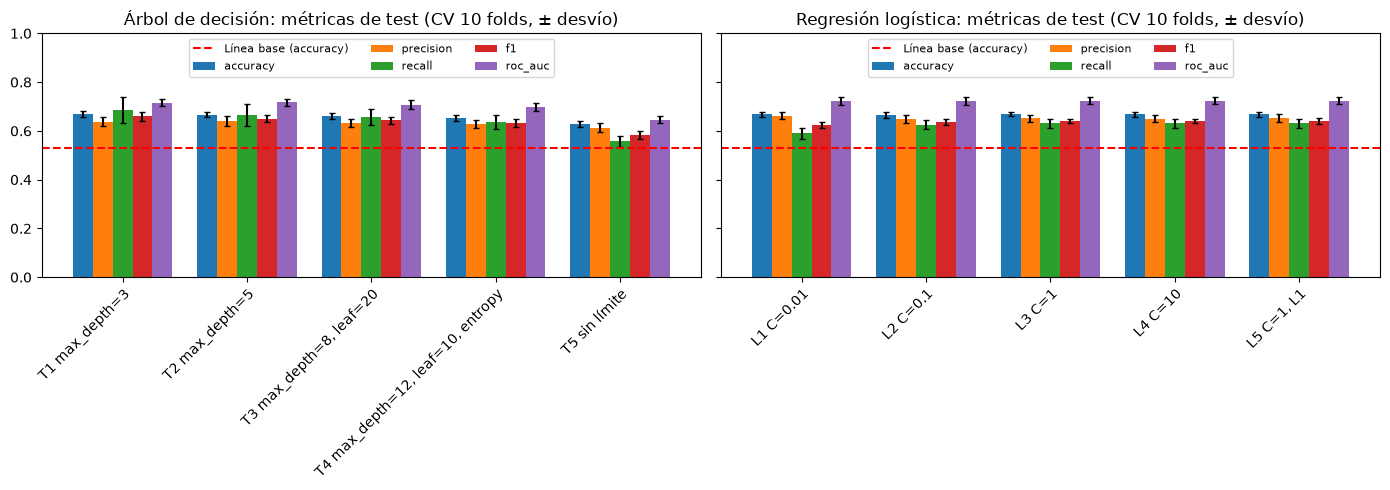

,accuracy,precision,recall,f1,roc_auc
tecnica,,,,,
Reg. logística,0.668,0.653,0.622,0.637,0.723
Árbol,0.655,0.630,0.641,0.634,0.697


In [10]:
# Métricas de cada configuración (promedio de los 10 folds)
comparacion = pd.concat([res_arbol.assign(tecnica='Árbol'), res_log.assign(tecnica='Reg. logística')])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (tecnica, res) in zip(axes, [('Árbol de decisión', res_arbol), ('Regresión logística', res_log)]):
    res[METRICAS].plot.bar(ax=ax, width=0.8, yerr=res[[f'{m}_std' for m in METRICAS]].values.T, capsize=2)
    ax.axhline(y.value_counts(normalize=True).max(), color='red', linestyle='--', label='Línea base (accuracy)')
    ax.set_ylim(0, 1)
    ax.set_title(f'{tecnica}: métricas de test (CV 10 folds, ± desvío)')
    ax.set_xlabel('')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    ax.legend(loc='upper center', ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

display(comparacion.groupby('tecnica')[METRICAS].mean().round(3))

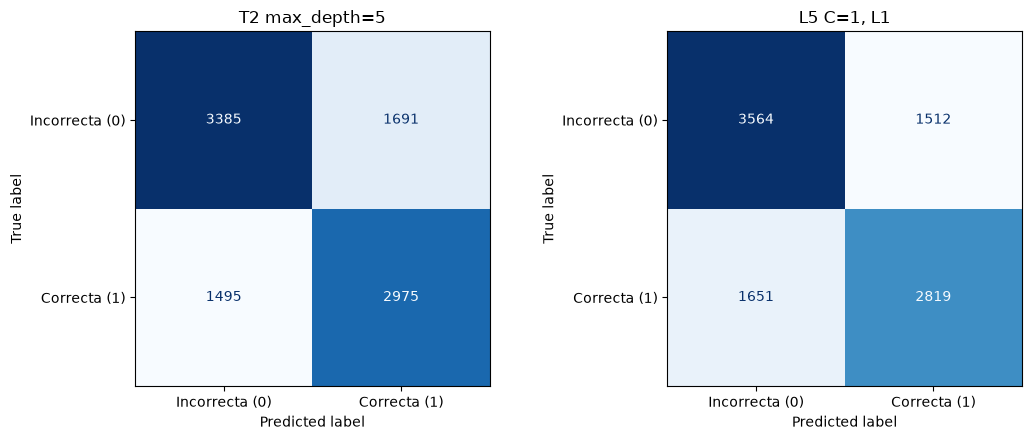

In [11]:
# Matriz de confusión de la mejor configuración de cada técnica (según AUC)
mejor_arbol = res_arbol['roc_auc'].idxmax()
mejor_log = res_log['roc_auc'].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nombre, modelo) in zip(axes, [(mejor_arbol, arboles[mejor_arbol]),
                                       (mejor_log, logisticas[mejor_log])]):
    y_pred = cross_val_predict(crear_pipeline(modelo), X_sel, y, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=['Incorrecta (0)', 'Correcta (1)'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

In [12]:
# Se guardan los resultados para el notebook 03 y el informe
comparacion.to_csv(RESULTADOS / 'resultados_tarea2.csv')
promedios.to_csv(RESULTADOS / 'promedios_tarea2.csv')
sel.to_csv(RESULTADOS / 'seleccion_caracteristicas.csv', index=False)
aporte_etl.to_csv(RESULTADOS / 'aporte_est_topic_level.csv', index=False)
print('Guardado en', RESULTADOS.relative_to(RAIZ))

Guardado en resultados


## 8. Conclusiones

**1. Ambas técnicas superan la línea base.** Un modelo que predijera siempre "incorrecta" acertaría el 53,2 % de los casos. Las mejores configuraciones de cada técnica alcanzan un 67 % de accuracy y un AUC de entre 0,717 y 0,723 (en promedio, 65,5 % para el árbol y 66,8 % para la logística), así que aprenden un patrón real a partir de los datos. Aun así, el problema es difícil: predecir si un estudiante responderá bien una pregunta tiene un componente impredecible que las variables disponibles no capturan.

**2. La variable `Est_Topic_Level` fue la mejora más importante.** Agregar la tasa de acierto de cada estudiante en cada tema y nivel (§3.2) subió el rendimiento de las dos técnicas en 1,4 a 1,9 puntos de accuracy. En cambio, las keywords no aportaron información (§3). Es decir, para este problema importa más conocer **al estudiante en el contexto de cada pregunta** que describir la pregunta con más detalle.

**3. Árbol de decisión: los árboles simples rinden mejor, y el overfitting se ve con claridad.** El rendimiento baja a medida que el árbol crece: T1 (`max_depth=3`) obtiene 0,670 de accuracy y T2 (`max_depth=5`) 0,666, con AUC de 0,716 y 0,717. Después, T3 baja a 0,660, T4 a 0,653 y el árbol sin límite (T5) cae a 0,628 de accuracy y 0,645 de AUC: al crecer sin restricciones memoriza el ruido del entrenamiento y generaliza peor. Que el mejor árbol sea uno de solo 3 niveles indica que el patrón de los datos es relativamente simple.

**4. Regresión logística: muy estable.** Las 5 configuraciones obtienen resultados casi idénticos (accuracy entre 0,666 y 0,669, AUC entre 0,722 y 0,723), y la configuración con penalización L1 (L5) rinde igual que L3, que tiene el mismo `C` con la penalización por defecto (L2). La única diferencia visible está en la regularización más fuerte (L1, `C=0,01`): mantiene el accuracy, pero se vuelve más conservadora para predecir "correcta" (recall 0,590 frente a 0,626–0,631 del resto, y la precision más alta, 0,663). Al ser un modelo lineal, aflojar la regularización no la lleva a sobreajustar.

**5. Las diferencias entre las mejores configuraciones son menores que la variabilidad entre folds.** El desvío del accuracy entre los 10 folds ronda los 0,9 a 1,4 puntos, mientras que las mejores configuraciones de cada técnica se diferencian por décimas. Por eso, aunque según el AUC las mejores son T2 (0,717) y L5 (0,723), en la práctica empatan con T1 y con L2–L4, respectivamente.

**6. Comparación entre técnicas.** Promediando las 5 configuraciones de cada una:

| Métrica | Árbol de decisión | Regresión logística |
|---|---|---|
| Accuracy | 0,655 (IC 95 %: 0,635 – 0,676) | 0,668 (IC 95 %: 0,666 – 0,669) |
| Precision | 0,630 | 0,653 |
| Recall | 0,641 | 0,622 |
| F1 | 0,634 | 0,637 |
| AUC | 0,697 (IC 95 %: 0,660 – 0,733) | 0,723 (IC 95 %: 0,722 – 0,723) |

La **regresión logística es superior** en accuracy, precision y AUC, y sobre todo **mucho más estable**: sus intervalos de confianza son muy angostos porque las 5 configuraciones dan resultados casi idénticos. El árbol es más sensible a la elección de hiperparámetros, y su promedio baja por el sobreajuste de T4 y T5. En cambio, el árbol obtiene un recall mayor: detecta más respuestas correctas, a costa de más falsos positivos.

**7. Matriz de confusión de la mejor configuración de cada técnica (según AUC).**

| | Árbol (T2, `max_depth=5`) | Regresión logística (L5, `C=1`, penalización L1) |
|---|---|---|
| Verdaderos negativos | 3.385 | 3.564 |
| Falsos positivos | 1.691 | 1.512 |
| Falsos negativos | 1.495 | 1.651 |
| Verdaderos positivos | 2.975 | 2.819 |
| Errores totales | 3.186 | 3.163 |

Las dos técnicas cometen una cantidad de errores muy parecida, pero de distinto tipo. El árbol detecta más respuestas correctas (66,6 % frente a 63,1 %) a costa de más falsos positivos, mientras que la regresión logística es más conservadora: reconoce mejor las respuestas incorrectas (70,2 % frente a 66,7 %), pero se le escapan más respuestas correctas.

**8. Implicancias para el Stacking.** Dos técnicas muy distintas (una basada en reglas y otra lineal) llegan a un rendimiento similar (≈ 67 %), aunque con errores de distinto tipo. En la Tarea 3 evaluaremos si combinarlas mediante Stacking aprovecha esa diferencia para mejorar el rendimiento. Como todos los modelos usan la misma información, es esperable que la mejora, si la hay, sea pequeña.

## 9. ¿En qué variables se apoyan los modelos?

Árbol y regresión logística son modelos de **caja blanca**: se puede ver qué variables usan para decidir. Esta sección analiza si los modelos se apoyan en muchas variables o si dependen de unas pocas, y si eso explica que el accuracy no supere el ~67 %. Se usan las mejores configuraciones de cada técnica (según AUC), con tres análisis complementarios:

1. **Importancia propia de cada modelo:** la importancia de cada variable en el árbol y los coeficientes de la regresión logística.
2. **Importancia por permutación:** cuánto cae el AUC en test si se "desordena" una variable al azar.
3. **Ablación:** el rendimiento usando solo algunas variables.

### 9.1 Importancia propia de cada modelo

Se entrena cada modelo con todos los datos, solo para interpretarlo (no para evaluarlo). En el árbol, la importancia indica cuánto contribuye cada variable a separar las clases (las importancias suman 1). En la regresión logística, el coeficiente indica cuánto sube (positivo) o baja (negativo) la probabilidad de respuesta correcta. Como todas las variables están entre 0 y 1 (tasas de acierto, one-hot y binarias), sus coeficientes se pueden comparar entre sí.

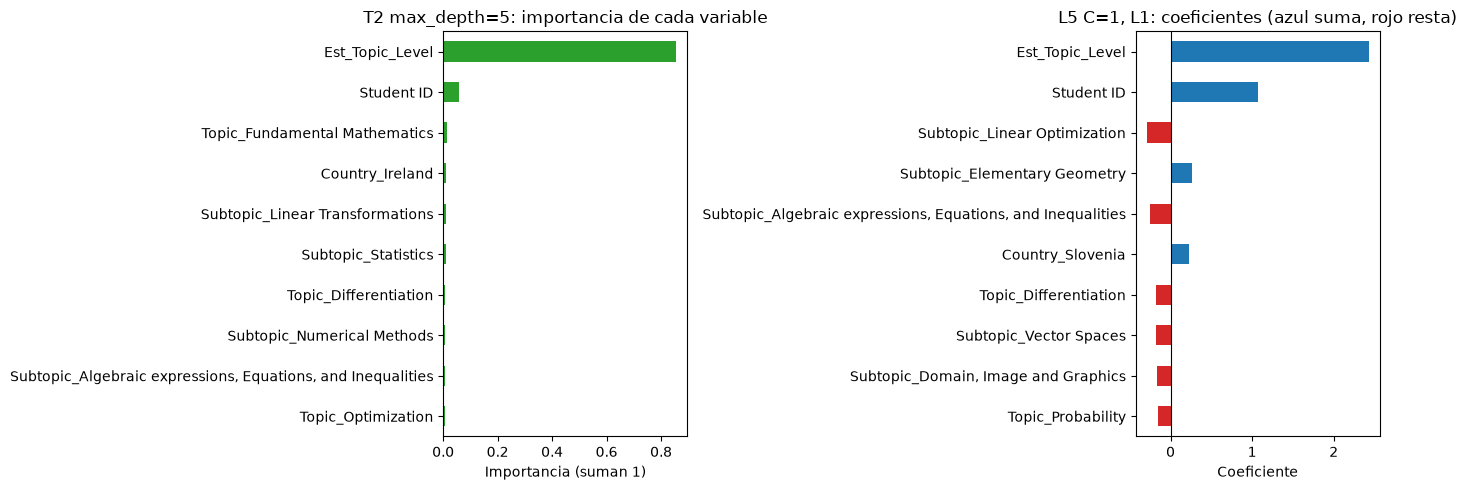

Árbol: Student ID + Est_Topic_Level concentran el 91% de la importancia; 15 de 49 variables tienen importancia mayor a 0.
Regresión logística: 31 de 49 coeficientes distintos de 0 (la penalización L1 anula el resto).


In [13]:
def nombres_variables(pipeline):
    """Nombres de las columnas que recibe el modelo, sin el prefijo del ColumnTransformer."""
    return [n.split('__', 1)[1] for n in pipeline[0].get_feature_names_out()]

pipe_arbol = crear_pipeline(arboles[mejor_arbol]).fit(X_sel, y)
pipe_log = crear_pipeline(logisticas[mejor_log]).fit(X_sel, y)

imp_arbol = pd.Series(pipe_arbol[-1].feature_importances_, index=nombres_variables(pipe_arbol))
coef_log = pd.Series(pipe_log[-1].coef_[0], index=nombres_variables(pipe_log))

top_arbol = imp_arbol.sort_values(ascending=False).head(10)
top_log = coef_log.reindex(coef_log.abs().sort_values(ascending=False).index).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_arbol[::-1].plot.barh(ax=axes[0], color='tab:green')
axes[0].set_title(f'{mejor_arbol}: importancia de cada variable')
axes[0].set_xlabel('Importancia (suman 1)')
top_log[::-1].plot.barh(ax=axes[1], color=['tab:blue' if v > 0 else 'tab:red' for v in top_log[::-1]])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title(f'{mejor_log}: coeficientes (azul suma, rojo resta)')
axes[1].set_xlabel('Coeficiente')
plt.tight_layout()
plt.show()

print(f'Árbol: Student ID + Est_Topic_Level concentran el {imp_arbol[COLS_TE].sum():.0%} de la importancia; '
      f'{(imp_arbol > 0).sum()} de {len(imp_arbol)} variables tienen importancia mayor a 0.')
print(f'Regresión logística: {(coef_log != 0).sum()} de {len(coef_log)} coeficientes distintos de 0 (la penalización L1 anula el resto).')

### 9.2 Importancia por permutación

La importancia propia depende de cómo funciona cada modelo. La **importancia por permutación** es una medida común a los dos: en cada fold de test se mezclan al azar los valores de una variable y se mide **cuánto cae el AUC**. Si el AUC cae mucho, el modelo depende de esa variable; si no cambia, no la usa. Se calcula con los mismos 10 folds, entrenando solo con el train de cada uno, así que no hay data leakage.

,T2 max_depth=5,"L5 C=1, L1"
Est_Topic_Level,0.1716,0.1292
Student ID,0.0360,0.0134
Subtopic_Linear Transformations,0.0039,-0.0001
Question Level,0.0027,0.0003
Country_Ireland,0.0022,0.0000
Subtopic_Vector Spaces,0.0000,0.0021
"Subtopic_Algebraic expressions, Equations, and Inequalities",0.0003,0.0012
Topic_Differentiation,0.0011,0.0006


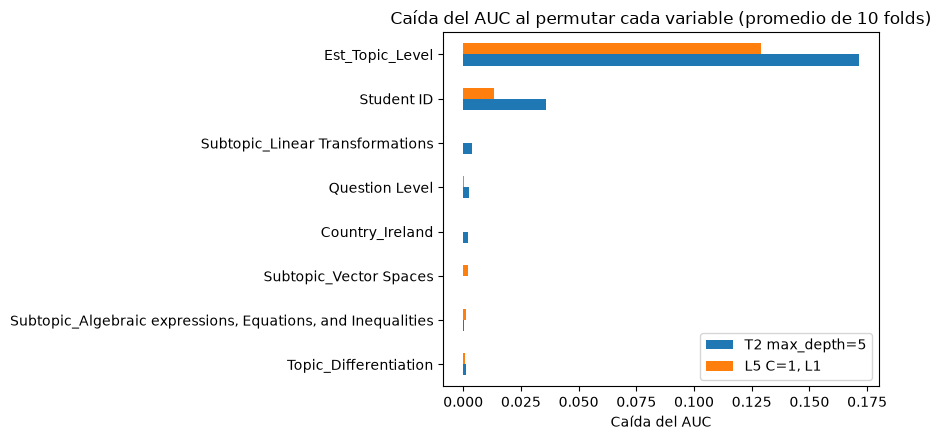

In [14]:
from sklearn.inspection import permutation_importance

def importancia_permutacion(modelo):
    """Caída promedio del AUC en test al permutar cada variable (10 folds, 5 repeticiones)."""
    caidas = []
    for train, test in cv.split(X_sel, y):
        pipe = crear_pipeline(modelo).fit(X_sel.iloc[train], y.iloc[train])
        r = permutation_importance(pipe, X_sel.iloc[test], y.iloc[test], scoring='roc_auc',
                                   n_repeats=5, random_state=SEMILLA, n_jobs=-1)
        caidas.append(r.importances_mean)
    return pd.Series(np.mean(caidas, axis=0), index=X_sel.columns)

perm = pd.DataFrame({mejor_arbol: importancia_permutacion(arboles[mejor_arbol]),
                     mejor_log: importancia_permutacion(logisticas[mejor_log])})
perm = perm.loc[perm.max(axis=1).sort_values(ascending=False).index]
display(perm.head(8).round(4))

perm.head(8)[::-1].plot.barh(figsize=(9, 4.5))
plt.title('Caída del AUC al permutar cada variable (promedio de 10 folds)')
plt.xlabel('Caída del AUC')
plt.tight_layout()
plt.show()

### 9.3 Ablación: ¿qué pasa si se usan solo algunas variables?

Para confirmar lo anterior, se evalúan las mejores configuraciones con tres conjuntos de variables, con el mismo esquema de cross-validation:

- **Todas:** las 49 columnas del conjunto elegido.
- **Solo historial del estudiante:** únicamente `Student ID` y `Est_Topic_Level` (con target encoding).
- **Sin historial del estudiante:** las 47 columnas restantes, que describen la pregunta y el país.

In [15]:
COLS_HISTORIAL = ['Student ID', 'Est_Topic_Level']
variantes = {
    'Todas (49)': (X_sel, COLS_TE),
    'Solo historial (2)': (X_sel[COLS_HISTORIAL], COLS_HISTORIAL),
    'Sin historial (47)': (X_sel.drop(columns=COLS_HISTORIAL), []),
}

filas = []
for nombre_var, (Xv, cols) in variantes.items():
    for nombre_mod, modelo in [(mejor_arbol, arboles[mejor_arbol]), (mejor_log, logisticas[mejor_log])]:
        filas.append({**evaluar(nombre_mod, modelo, Xv, y, cols_te=cols), 'variables': nombre_var})

ablacion = pd.DataFrame(filas).pivot_table(index='variables', columns='modelo', values=['accuracy', 'roc_auc'])
display(ablacion.loc[list(variantes)].round(3))
print('Línea base (accuracy):', round(y.value_counts(normalize=True).max(), 3))

accuracy                   roc_auc               
modelo             L5 C=1, L1 T2 max_depth=5 L5 C=1, L1 T2 max_depth=5
variables                                                             
Todas (49)              0.669          0.666      0.723          0.717
Solo historial (2)      0.671          0.664      0.722          0.709
Sin historial (47)      0.579          0.579      0.595          0.580

Línea base (accuracy): 0.532


In [16]:
# Las primeras reglas del árbol: un árbol de profundidad 3 (T1) muestra cómo decide
from sklearn.tree import export_text

pipe_t1 = crear_pipeline(arboles['T1 max_depth=3']).fit(X_sel, y)
print(export_text(pipe_t1[-1], feature_names=nombres_variables(pipe_t1), decimals=2))

|--- Est_Topic_Level <= 0.47
|   |--- Est_Topic_Level <= 0.27
|   |   |--- Student ID <= 0.31
|   |   |   |--- class: 0
|   |   |--- Student ID >  0.31
|   |   |   |--- class: 0
|   |--- Est_Topic_Level >  0.27
|   |   |--- Topic_Differentiation <= 0.50
|   |   |   |--- class: 0
|   |   |--- Topic_Differentiation >  0.50
|   |   |   |--- class: 0
|--- Est_Topic_Level >  0.47
|   |--- Est_Topic_Level <= 0.65
|   |   |--- Country_Ireland <= 0.50
|   |   |   |--- class: 1
|   |   |--- Country_Ireland >  0.50
|   |   |   |--- class: 0
|   |--- Est_Topic_Level >  0.65
|   |   |--- Subtopic_Linear Transformations <= 0.50
|   |   |   |--- class: 1
|   |   |--- Subtopic_Linear Transformations >  0.50
|   |   |   |--- class: 1



**Conclusión:** los modelos **no dependen de ninguna variable espuria**: se apoyan en el historial del estudiante, que es la información que tiene sentido para predecir si va a responder bien.

- En el árbol, `Student ID` y `Est_Topic_Level` concentran el 91 % de la importancia, y `Est_Topic_Level` sola el 85 %. Su primera regla lo resume: si la tasa de acierto del estudiante en ese tema y nivel supera 0,47, predice "correcta".
- En la regresión logística, los coeficientes más grandes son los de `Est_Topic_Level` (2,43) y `Student ID` (1,07). Los de las variables de la pregunta y del país no superan 0,29 en valor absoluto.
- Al permutar `Est_Topic_Level`, el AUC cae 0,17 en el árbol y 0,13 en la logística. Ninguna variable de país lo hace caer más de 0,002, y ninguna variable de la pregunta, más de 0,004.
- El país aparece solo con efectos menores: Irlanda en una regla del tercer nivel del árbol y Eslovenia con un coeficiente de 0,23 en la logística. Como se vio en el EDA (§3.1), la tasa alta de Eslovenia se debe a sus 3 estudiantes, no al país.
- **Usando solo las 2 variables de historial, los modelos rinden igual que con las 49** (logística: 0,671 de accuracy y 0,722 de AUC). **Sin ellas, caen a 0,579 de accuracy y un AUC de 0,58 a 0,60**, apenas por encima de la línea base (0,532).

Por lo tanto, el techo de ~67 % **no se debe a que el modelo ponga el peso en variables equivocadas**. Se debe a que el dataset no incluye variables que expliquen por qué un estudiante acierta una pregunta en particular, como la dificultad real de cada pregunta, el tiempo de respuesta o el orden de los intentos. Las características de la pregunta y el país casi no agregan información más allá del historial. Una consecuencia de esto es que el modelo no puede predecir bien a estudiantes nuevos, que no tienen historial.

Sin `Est_Topic_Level`, los modelos pierden entre 1,5 y 2 puntos de accuracy y pasan a apoyarse en `Student ID` (89 % de la importancia en el árbol). La dependencia del historial no la genera la variable creada: es la señal principal del dataset, y `Est_Topic_Level` solo la refina al separarla por tema y nivel.